In [1]:
# conda env 'at3d_pure_k9'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import netCDF4 as nc
from collections import OrderedDict
from src.utils.util import load_sensor_dict
from src.utils.util import save_sensor_dict

In [2]:
## INPUT
lut_file = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'LUT_RF17.nc'
# lut_file = './LUT_RF17.nc'
# lut_file = './LUT_1D.nc'
# obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
# rte_grid_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/RTG_1400.nc'
rte_grid_file = INTERIM_DATA / 'RTG_default.nc'

## OUTPUT
out_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_1DTAU_CAMP2Ex_RF17_default_1400.nc'
out_file = INTERIM_DATA / 'AT3D_1DTAU_CAMP2Ex_RF17_default.nc'

In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
obs = load_sensor_dict(obs_file)
LUT = xr.load_dataset(lut_file)

In [4]:
LUT

<xarray.Dataset>
Dimensions:  (brf: 100)
Coordinates:
  * brf      (brf) float64 0.03297 0.04184 0.04245 0.04311 ... 1.076 1.087 1.097
Data variables:
    tau      (brf) float64 0.0 0.115 0.123 0.1316 ... 69.76 74.63 79.83 85.4

In [5]:
np.all(np.diff(LUT.brf.data) > 0)

True

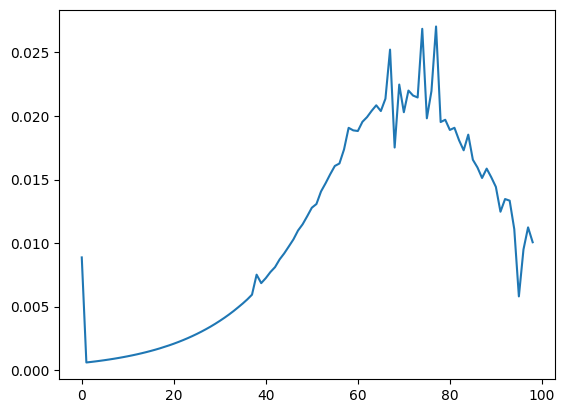

In [6]:
plt.plot(np.diff(LUT.brf))

In [7]:
cam = obs['MISR']['sensor_list'][4]
measured_brf = (cam.I.copy(deep=True)*np.pi/cam.mu0).data
measured_tau = np.zeros(measured_brf.shape)
for i, m_brf in enumerate(measured_brf):
    measured_tau[i] = LUT.sel(brf=m_brf, method='nearest').tau.data
measured_tau[measured_tau <= np.min(LUT.tau.data)] = 0
cam['tau'] = (['nrays'], measured_tau)

In [8]:
np.min(LUT.brf.data)

0.03296757725075786

In [9]:
np.min(LUT.tau.data)

0.0

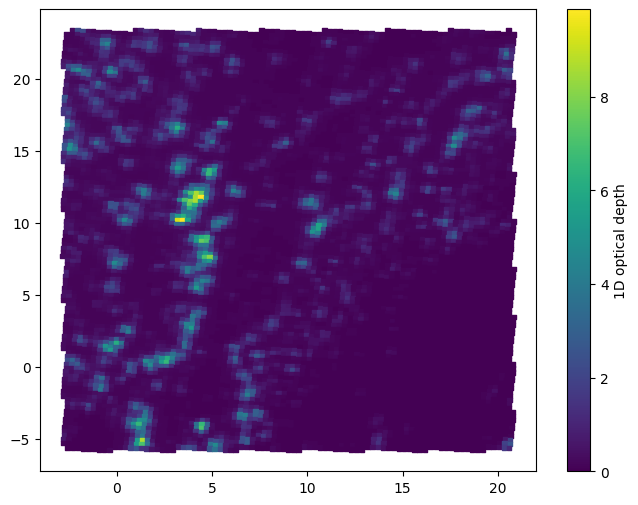

In [10]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
# c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, norm=colors.LogNorm(vmin=0.1, vmax=10))
c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, vmin=0.0, vmax=None)
plt.colorbar(c, label='1D optical depth')

In [11]:
save_sensor_dict(out_file, obs)

Saved sensors to: /data/gdi/b/johntl3/LundstromPub2025/data/interim/AT3D_1DTAU_CAMP2Ex_RF17_default.nc
